![Tutorial_banner](images/cbens_2026_performancetutorial_logo.jpg)


# PARTE 2 — Modelagem de um sistema fotovoltaico real com pvlib

## Simon Solar: do recurso solar à energia AC

Neste exercício, vamos utilizar **pvlib-python** para estimar a produção de uma usina fotovoltaica real com uma abordagem **PVWatts**. A sequência é semelhante à utilizada anteriormente: posição solar → irradiância no plano dos módulos → temperatura da célula → potência DC → potência AC → energia.

Vamos trabalhar com **um arquivo meteorológico NSRDB já disponibilizado**. Não será necessário baixar dados ou configurar credenciais.

**Objetivo:** ao final, construir uma estimativa horária da produção e identificar quais hipóteses do modelo ainda precisam ser verificadas com medições reais.

> **Observação:** este exercício usa as funções simplificadas de PVWatts disponíveis no pvlib. Não pretende reproduzir exatamente o modelo completo PVWatts V8 de SAM.
> 

## A instalação: Simon Solar

A usina Simon Solar está localizada na Geórgia (EUA). Vamos tratá-la inicialmente como **um único sistema equivalente**, sem resolver curvas I–V individuais nem a configuração elétrica de cada string.

**Localização e configuração conhecida**

| Parâmetro | Informação |
|---|---|
| Latitude | 33.6762° N |
| Longitude | −83.67633° |
| Capacidade nominal instalada | aproximadamente **38.6 MWdc** |
| Estrutura | fixa, em rack aberto |
| Inclinação | **20°** |
| Azimute da superfície | **180°**, sul |
| Relação DC/AC | **1.17** |
| Eficiência nominal do inversor | **96%** |
| Coeficiente equivalente de potência | **−0.42%/°C**, aproximação inicial |
| Perdas agregadas do sistema | **9.87%**, cenário de referência |

**O que sabemos e o que estamos simplificando?**

Temos a capacidade instalada e informações gerais de orientação e equipamentos. Para o exercício, representaremos o conjunto por um **coeficiente de temperatura equivalente**. Esse coeficiente é uma aproximação derivada dos metadados disponíveis, não um modelo detalhado de módulos específicos.

**Perguntas para começar:** Qual é a capacidade AC aproximada? Por que um modelo agregado pode estimar potência sem o número de módulos em cada string? O que se perde ao não calcular a curva I–V?


![Satellite image of Simon Solar](images/9069_sat_image.png)



## Etapa 1 — Instalar e importar as bibliotecas

No Colab, execute a primeira célula para instalar `pvlib`. Em Jupyter local, se a biblioteca já estiver instalada, você pode pular a instalação.

In [1]:
from pathlib import Path
import subprocess
import shutil
import importlib.util

if importlib.util.find_spec("pvlib") is None:
    %pip install -q pvlib ipywidgets
    
REPO_URL = "https://github.com/PV-Tutorials/2026_pvlib-and-performance_CBENS.git"

# No Colab, os arquivos do repositório não são baixados automaticamente.
if Path("/content").exists():
    repo_dir = Path("/content/2026_pvlib-and-performance_CBENS")

    if not repo_dir.exists():
        subprocess.run(
            ["git", "clone", "--depth", "1", REPO_URL, str(repo_dir)],
            check=True
        )

    # Disponibilizar as pastas no diretório de trabalho do notebook
    for folder in ["weather_data", "field_data", "results"]:
        source = repo_dir / folder
        destination = Path.cwd() / folder

        if source.exists() and not destination.exists():
            shutil.copytree(source, destination)

# Verificar os arquivos disponíveis
for folder in ["weather_data", "field_data", "results"]:
    path = Path(folder)
    files = list(path.glob("*.csv")) if path.exists() else []
    print(f"{folder}: {len(files)} arquivos CSV")

weather_data: 9 arquivos CSV
field_data: 3 arquivos CSV
results: 2 arquivos CSV


In [2]:
import pvlib
import pandas as pd
import matplotlib.pyplot as plt

print("pvlib:", pvlib.__version__)

pvlib: 0.16.1


## Etapa 2 — Ler um arquivo meteorológico NSRDB

Vamos começar com **apenas um ano**. O arquivo CSV estará na mesma pasta do notebook (ou será disponibilizado no Colab).

Os arquivos NSRDB no formato SAM incluem cabeçalhos de metadados, além das colunas meteorológicas. A função `read_nsrdb_psm4` reconhece esse formato e renomeia as variáveis quando possível.

Confira se os dados contêm as grandezas necessárias: `ghi`, `dni`, `dhi`, `temp_air` e `wind_speed`.

> Os horários devem estar coerentes com o fuso do local. Não remova o fuso horário do índice sem verificar o significado dos timestamps.

In [3]:
# TODO: substituir pelo nome do arquivo NSRDB fornecido
from pathlib import Path

weather_file = Path("weather_data") / "nsrdb_33.6762_-83.67633_nsrdb-GOES-aggregated-v4-0-0_60_2016.csv"

weather, weather_meta = pvlib.iotools.read_nsrdb_psm4(
    weather_file, map_variables=True
)

print(weather.index.min(), "até", weather.index.max())
print("Intervalo típico:", weather.index.to_series().diff().median())
print("Colunas:", list(weather.columns))
display(weather.head())

2016-01-01 00:30:00-05:00 até 2016-12-31 23:30:00-05:00
Intervalo típico: 0 days 01:00:00
Colunas: ['Year', 'Month', 'Day', 'Hour', 'Minute', 'temp_air', 'Alpha', 'Aerosol Optical Depth', 'Asymmetry', 'dhi_clear', 'dni_clear', 'ghi_clear', 'Cloud Fill Flag', 'Cloud Type', 'temp_dew', 'dhi', 'dni', 'Fill Flag', 'ghi', 'Ozone', 'relative_humidity', 'solar_zenith', 'SSA', 'albedo', 'pressure', 'precipitable_water', 'wind_direction', 'wind_speed', 'Global Horizontal UV Irradiance (280-400nm)', 'Global Horizontal UV Irradiance (295-385nm)']


,Year,Month,Day,Hour,Minute,temp_air,Alpha,Aerosol Optical Depth,Asymmetry,dhi_clear,...,relative_humidity,solar_zenith,SSA,albedo,pressure,precipitable_water,wind_direction,wind_speed,Global Horizontal UV Irradiance (280-400nm),Global Horizontal UV Irradiance (295-385nm)
2016-01-01 00:30:00-05:00,2016,1,1,0,30,8.8,1.32,0.049,0.62,0.0,...,94.19,169.21,0.95,0.12,992.0,1.8,305.0,0.5,0.0,0.0
2016-01-01 01:30:00-05:00,2016,1,1,1,30,8.3,1.31,0.048,0.62,0.0,...,95.05,164.37,0.95,0.12,992.0,1.8,305.0,0.5,0.0,0.0
2016-01-01 02:30:00-05:00,2016,1,1,2,30,7.7,1.33,0.046,0.62,0.0,...,96.71,153.24,0.95,0.12,992.0,1.7,310.0,0.5,0.0,0.0
2016-01-01 03:30:00-05:00,2016,1,1,3,30,7.0,1.36,0.043,0.62,0.0,...,98.49,140.97,0.94,0.12,992.0,1.4,313.0,0.5,0.0,0.0
2016-01-01 04:30:00-05:00,2016,1,1,4,30,6.3,1.38,0.042,0.62,0.0,...,99.30,128.50,0.94,0.12,992.0,1.3,317.0,0.5,0.0,0.0


## Etapa 3 — Definir a localização e calcular a posição solar

A posição solar depende do local e do instante de tempo. Precisaremos do **zênite** e do **azimute** solar para transformar a irradiância horizontal em irradiância no plano dos módulos.

A documentação de referência é [`Location.get_solarposition`](https://pvlib-python.readthedocs.io/en/stable/reference/generated/pvlib.location.Location.get_solarposition.html).

In [5]:
# Latitude e longitude da usina
latitude = 33.6762
longitude = -83.67633

location = pvlib.location.Location(
    latitude=latitude,
    longitude=longitude,
    tz="America/New_York",
    name="Simon Solar"
)

# Calcular a posição solar para os horários do arquivo
solar_position = location.get_solarposition(weather.index)

display(solar_position[["apparent_zenith", "azimuth"]].head())

,apparent_zenith,azimuth
2016-01-01 00:30:00-05:00,169.225781,350.248276
2016-01-01 01:30:00-05:00,164.390674,50.412015
2016-01-01 02:30:00-05:00,153.259635,73.890459
2016-01-01 03:30:00-05:00,140.981740,85.668918
2016-01-01 04:30:00-05:00,128.513069,94.043563


## Etapa 4 — Calcular a irradiância no plano do módulo (POA)

O NSRDB fornece irradiância global horizontal (**GHI**), direta normal (**DNI**) e difusa horizontal (**DHI**). Mas o plano dos módulos está inclinado.

Para estimar a irradiância incidente no módulo, usamos [`pvlib.irradiance.get_total_irradiance`](https://pvlib-python.readthedocs.io/en/stable/reference/generated/pvlib.irradiance.get_total_irradiance.html).

**Qual é a diferença entre GHI e POA?** Como a inclinação e o azimute alteram a energia disponível?

Neste primeiro modelo vamos usar transposição isotrópica e um albedo fixo de **0.20**. São hipóteses simplificadoras que poderão ser avaliadas depois.

,poa_global,poa_direct,poa_diffuse,poa_sky_diffuse,poa_ground_diffuse
2016-01-01 00:30:00-05:00,0.0,0.0,0.0,0.0,0.0
2016-01-01 01:30:00-05:00,0.0,0.0,0.0,0.0,0.0
2016-01-01 02:30:00-05:00,0.0,0.0,0.0,0.0,0.0
2016-01-01 03:30:00-05:00,0.0,0.0,0.0,0.0,0.0
2016-01-01 04:30:00-05:00,0.0,0.0,0.0,0.0,0.0


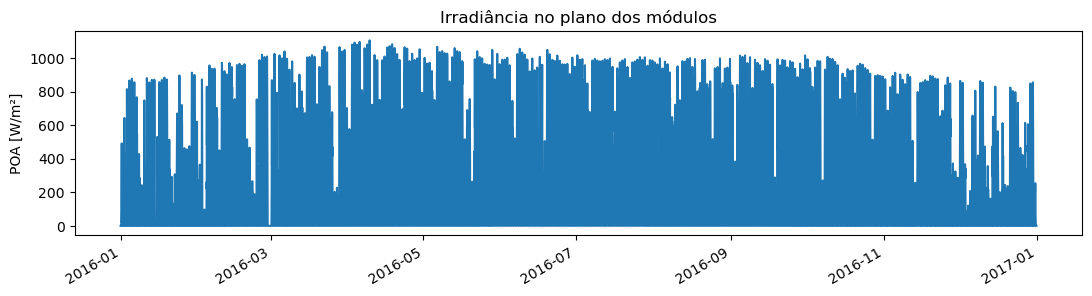

In [6]:
# Orientação conhecida da instalação
surface_tilt = 20       # graus
surface_azimuth = 180   # graus, 180 = sul
albedo = 0.20           # hipótese inicial

# Calcular POA com get_total_irradiance
poa = pvlib.irradiance.get_total_irradiance(
    surface_tilt=surface_tilt,
    surface_azimuth=surface_azimuth,
    solar_zenith=solar_position["apparent_zenith"],
    solar_azimuth=solar_position["azimuth"],
    dni=weather["dni"],
    ghi=weather["ghi"],
    dhi=weather["dhi"],
    albedo=albedo,
    model="isotropic"
)

# Compare as componentes de irradiância
display(poa.head())
poa["poa_global"].plot(figsize=(13, 3), title="Irradiância no plano dos módulos")
plt.ylabel("POA [W/m²]")
plt.show()

## Etapa 5 — Estimar a temperatura da célula

O modelo de potência precisa da temperatura da **célula fotovoltaica**, que em geral é diferente da temperatura ambiente. O pvlib oferece diferentes modelos térmicos; neste exercício, utilizaremos **SAPM** e parâmetros típicos de uma montagem aberta.

A função [`pvlib.temperature.sapm_cell`](https://pvlib-python.readthedocs.io/en/stable/reference/generated/pvlib.temperature.sapm_cell.html) utiliza irradiância POA, temperatura ambiente e velocidade do vento.

**Discussão:** o que pode acontecer com a potência produzida em uma tarde muito quente, mesmo com irradiância elevada?

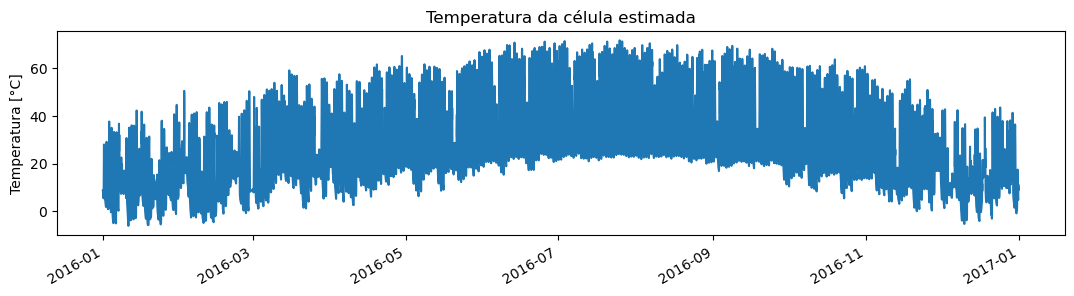

In [7]:
# Parâmetros térmicos para montagem aberta (hipótese simplificada)
temp_params = pvlib.temperature.TEMPERATURE_MODEL_PARAMETERS["sapm"]["open_rack_glass_glass"]

# Estimar a temperatura da célula com sapm_cell
cell_temperature = pvlib.temperature.sapm_cell(
    poa_global=poa["poa_global"],
    temp_air=weather["temp_air"],
    wind_speed=weather["wind_speed"],
    **temp_params
)

cell_temperature.plot(figsize=(13, 3), title="Temperatura da célula estimada")
plt.ylabel("Temperatura [°C]")
plt.show()


## Etapa 6 — Calcular a potência DC

Com a irradiância no plano dos módulos (POA) e a temperatura das células calculadas, podemos estimar a potência DC produzida pelo sistema fotovoltaico.

Existem diferentes abordagens de modelagem disponíveis no **pvlib**, incluindo:

- **Modelos simplificados de potência**, como o PVWatts, que estimam a potência máxima a partir da irradiância, temperatura e potência nominal.
- **Modelos elétricos de diodo único**, como os utilizados no PVsyst e SAM, que representam o comportamento elétrico dos módulos e permitem calcular a curva corrente–tensão (I–V).
- **Modelos empíricos**, como o Sandia Array Performance Model (SAPM), que utilizam parâmetros obtidos experimentalmente para representar o desempenho dos módulos.

Cada abordagem exige diferentes parâmetros de entrada e apresenta diferentes níveis de complexidade. Todas permitem estimar a potência no ponto de máxima potência (MPP), mas os modelos elétricos mais detalhados também podem estimar outras grandezas, como tensão de circuito aberto e corrente de curto-circuito.

### Nossa escolha: PVWatts

Neste exercício, utilizaremos o modelo simplificado [`pvlib.pvsystem.pvwatts_dc`](https://pvlib-python.readthedocs.io/en/stable/reference/generated/pvlib.pvsystem.pvwatts_dc.html).

O PVWatts estima a potência DC máxima disponível utilizando a irradiância efetiva, a temperatura das células, a potência nominal instalada e o coeficiente de temperatura da potência.

Essa abordagem é especialmente útil quando conhecemos as características gerais de uma usina, mas não dispomos de todos os parâmetros elétricos dos módulos.

**Atenção às unidades:**
- `pdc0`: potência nominal em **W**
- `g_poa_effective`: irradiância efetiva em **W/m²**
- `temp_cell`: temperatura da célula em **°C**
- `gamma_pdc`: coeficiente de temperatura em **1/°C** (não em %/°C)

Neste exercício, estamos modelando **a usina inteira**, e não um módulo individual.

**Simplificação:** utilizaremos diretamente `poa_global` como irradiância efetiva, sem aplicar uma correção explícita para perdas ópticas por ângulo de incidência (IAM). Discutiremos essa hipótese e suas possíveis consequências na avaliação das incertezas do modelo.


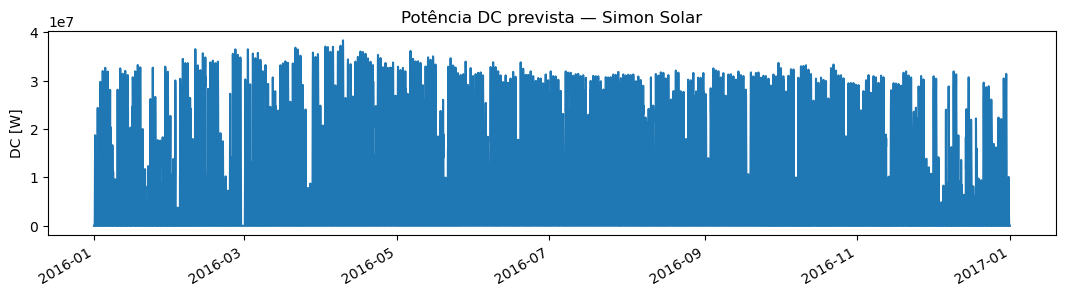

In [9]:
# Potência nominal da usina (38.6 MWdc → W)
pdc0 = 38_600_000  # W

# Coeficiente de temperatura (-0.42 %/°C → 1/°C)
gamma_pdc = -0.0042

# Estimar a potência DC com pvwatts_dc
pdc = pvlib.pvsystem.pvwatts_dc(
    effective_irradiance=poa["poa_global"],
    temp_cell=cell_temperature,
    pdc0=pdc0,
    gamma_pdc=gamma_pdc
)

pdc = pd.Series(pdc, index=weather.index, name="dc_power_w")
pdc.plot(figsize=(13, 3), title="Potência DC prevista — Simon Solar")
plt.ylabel("DC [W]")
plt.show()

## Etapa 7 — Aplicar perdas agregadas e converter DC → AC

Nem toda a potência DC calculada chega à entrada do inversor: podemos representar efeitos não explicitamente modelados por uma **perda agregada**.

Aqui utilizaremos **9.87%** como hipótese inicial de perdas do sistema. A seguir, o modelo de inversor PVWatts calcula eficiência de conversão e limita a potência AC à capacidade nominal (**clipping**).

**Importante:** essas perdas agregadas **não são uma taxa anual de degradação**. Por enquanto, estamos simulando somente o desempenho de um ano, sem aplicar envelhecimento nem indisponibilidade variável dos inversores.

A função [`pvlib.inverter.pvwatts`](https://pvlib-python.readthedocs.io/en/stable/reference/generated/pvlib.inverter.pvwatts.html) espera como `pdc0` a *potência DC de entrada correspondente à potência AC nominal*, que **não** é necessariamente o `pdc0` da usina usado na etapa anterior.

In [ ]:
# Relação DC/AC e eficiência nominal do inversor
DC_AC_ratio = 1.17
eta_inv_nom = 0.96      # fração, não %
losses_percent = 9.87

# Potência AC nominal da usina (W)
pac0 = pdc0 / DC_AC_ratio

# Potência DC de entrada nominal para o modelo do inversor (W)
inverter_pdc0 = pac0 / eta_inv_nom

# Aplicar as perdas agregadas ANTES do inversor
pdc_after_losses = pdc * (1 - losses_percent / 100)

# Calcular a potência AC
pac = pvlib.inverter.pvwatts(
    pdc=pdc_after_losses,
    pdc0=inverter_pdc0,
    eta_inv_nom=eta_inv_nom
)

pac = pd.Series(pac, index=weather.index, name="ac_power_w")
print(f"Capacidade nominal AC: {pac0/1e6:.2f} MW")

## Etapa 8 — Visualizar e calcular a energia

Agora temos uma série temporal de **potência horária DC e AC**. Potência é medida em W ou MW; **energia** é calculada integrando a potência ao longo do tempo.

Se o arquivo tem amostras regulares representativas de **uma hora**, cada potência média multiplicada por 1 h gera energia em Wh. **Antes de usar a soma como energia anual**, confirme que o arquivo contém um ano completo sem lacunas e que os timestamps são realmente horários.

**Perguntas:** Onde observamos clipping? Por que as curvas DC e AC não são iguais? Quais são as unidades do valor anual?

In [ ]:
results = pd.DataFrame({
    "dc_power_mw": pdc / 1e6,
    "ac_power_mw": pac / 1e6,
}, index=weather.index)

results.plot(figsize=(14, 4), linewidth=0.7, title="Simon Solar — Potência modelada")
plt.ylabel("Potência [MW]")
plt.grid(alpha=0.3)
plt.show()

# TODO: verificar o intervalo temporal e a completude dos dados
step_hours = weather.index.to_series().diff().median() / pd.Timedelta(hours=1)
print("Intervalo entre registros [h]:", step_hours)

# TODO: calcular energia do período em MWh, para dados regulares sem lacunas
energy_mwh = ...
print(f"Energia modelada para o período: {energy_mwh:,.0f} MWh")

## Etapa 9 — Reflita sobre o modelo

1. Por que **38.6 MWdc** basta para estimar a potência agregada, mesmo sem modelar individualmente curvas I–V?
2. Como mudaria a produção se a inclinação fosse diferente? E se o coeficiente de temperatura fosse mais negativo?
3. Por que a relação DC/AC altera o comportamento de clipping?
4. Quais parâmetros representam **características físicas conhecidas** e quais são **hipóteses de modelagem**?
5. Que informações adicionais seriam necessárias para calcular curvas I–V, correntes e tensões por string?
6. O que o modelo **não captura** (paradas de inversores, degradação ao longo dos anos, sujeira variável, sombreamento localizado, erros de medição)?

### Na próxima sessão: comparação com medições

Na parte da tarde, vamos comparar a saída do modelo com dados operacionais da usina, investigar discrepâncias e discutir qualidade de dados, perdas e incerteza. **O objetivo não é apenas obter uma curva, mas avaliar quando podemos confiar nela.**

### Referências

- [Documentação pvlib-python](https://pvlib-python.readthedocs.io/)
- [Leitura de arquivos NSRDB PSM4](https://pvlib-python.readthedocs.io/en/stable/reference/generated/pvlib.iotools.read_nsrdb_psm4.html)
- [PVWatts DC](https://pvlib-python.readthedocs.io/en/stable/reference/generated/pvlib.pvsystem.pvwatts_dc.html)
- [PVWatts inverter](https://pvlib-python.readthedocs.io/en/stable/reference/generated/pvlib.inverter.pvwatts.html)

*Estrutura adaptada do tutorial PV Systems Modeling with Python (PVSC 2025), com o estudo de caso Simon Solar.*

[![Creative Commons License](https://i.creativecommons.org/l/by/4.0/88x31.png)](http://creativecommons.org/licenses/by/4.0/)

This work is licensed under a [Creative Commons Attribution 4.0 International License](http://creativecommons.org/licenses/by/4.0/).